In [ ]:
import os
import random
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.preprocessing.image import load_img, img_to_array

IMAGES_DIR = '../data/images/'
MASKS_DIR = '../data/annotations/trimaps/'

image_filenames = [f for f in os.listdir(IMAGES_DIR) if f.endswith('.jpg')]
image_filenames.sort()

print(f"Total images found: {len(image_filenames)}")

Matplotlib is building the font cache; this may take a moment.


Total images found: 7390


In [5]:
def load_and_preprocess_mask(mask_path, target_size=(256, 256)):
    """
    Loads a mask and maps:
    - 2.0 (Background) to 0.0
    - 3.0 (Boundary) to 1.0 (Foreground)
    - 1.0 (Foreground) remains 1.0
    """

    mask = load_img(mask_path, target_size=target_size, color_mode="grayscale")
    mask = img_to_array(mask)
    

    mask[mask == 2.0] = 0.0  
    mask[mask == 3.0] = 1.0  
    
    return mask

In [ ]:
def plot_3x3_overlays(image_filenames, images_dir, masks_dir, target_size=(256, 256)):
    selected_files = random.sample(image_filenames, 9)
    
    fig, axes = plt.subplots(3, 3, figsize=(12, 12))
    axes = axes.flatten()
    
    for i, file_name in enumerate(selected_files):
        img_path = os.path.join(images_dir, file_name)
        mask_name = file_name.replace('.jpg', '.png')
        mask_path = os.path.join(masks_dir, mask_name)
        
        if not os.path.exists(mask_path):
            continue
            

        img = load_img(img_path, target_size=target_size)
        img_arr = img_to_array(img) / 255.0  
        

        mask_arr = load_and_preprocess_mask(mask_path, target_size)
        
        overlay = img_arr.copy()
        overlay[mask_arr[:, :, 0] == 1.0] = overlay[mask_arr[:, :, 0] == 1.0] * 0.5 + [0.5, 0, 0]
        
        # Plot
        axes[i].imshow(overlay)
        axes[i].set_title(file_name, fontsize=10)
        axes[i].axis('off')
        
    plt.tight_layout()
    plt.show()

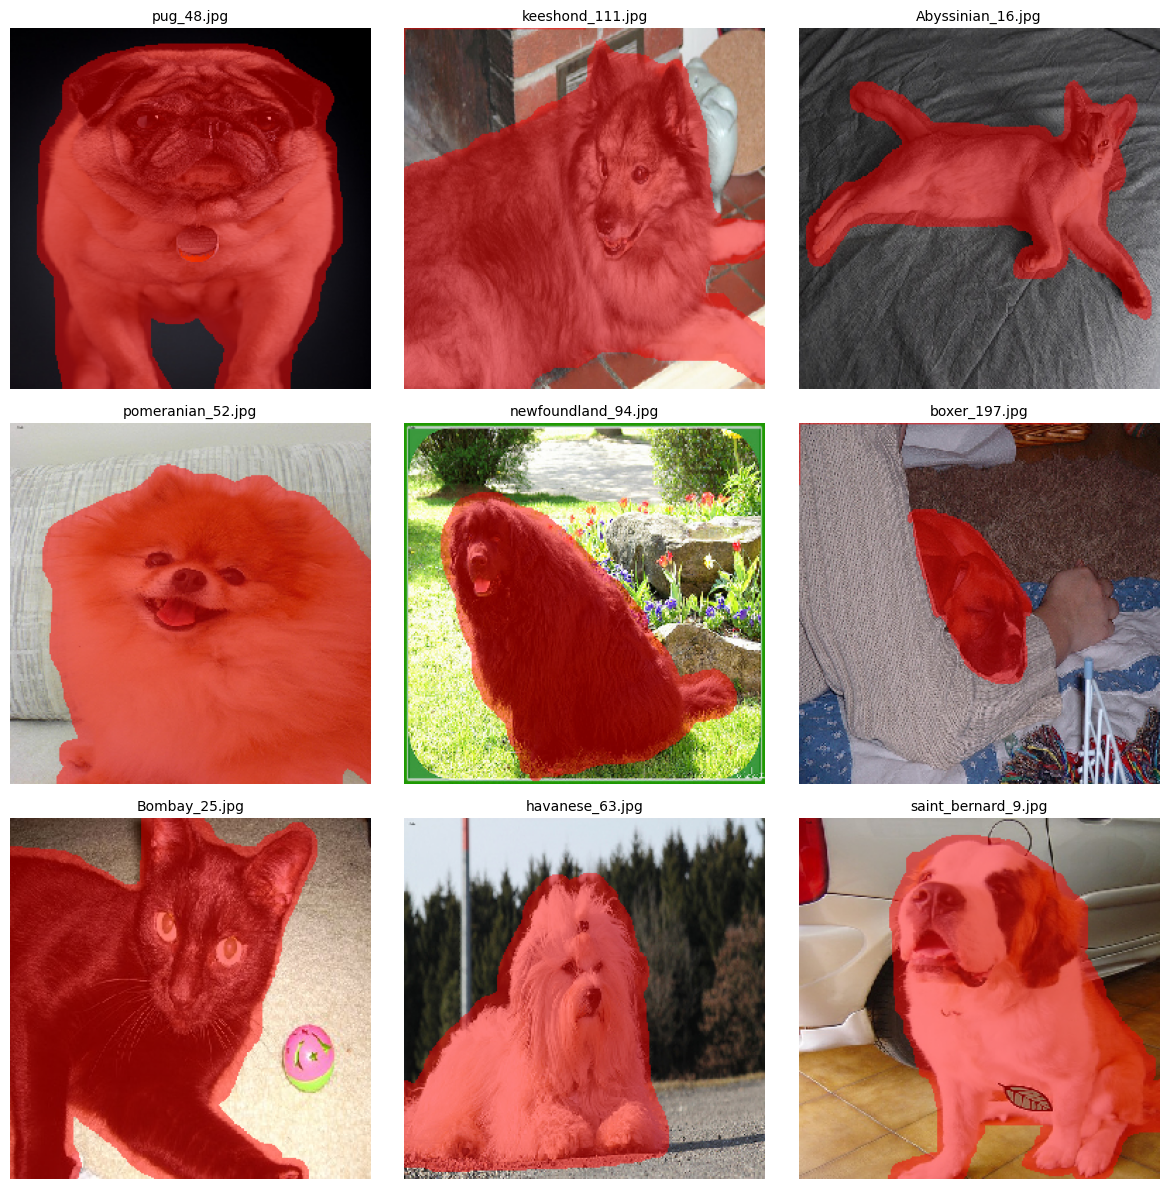

In [7]:
plot_3x3_overlays(image_filenames, IMAGES_DIR, MASKS_DIR)